# K Means Clustering Algorithms Implementation

In [1]:
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
import pandas as pd
import numpy as np
%matplotlib inline

We actually dont use y that much we only use X

In [7]:
X, y = make_blobs(n_samples=1000, centers=3, n_features=2,
                  random_state=23)

In [8]:
X.shape

(1000, 2)

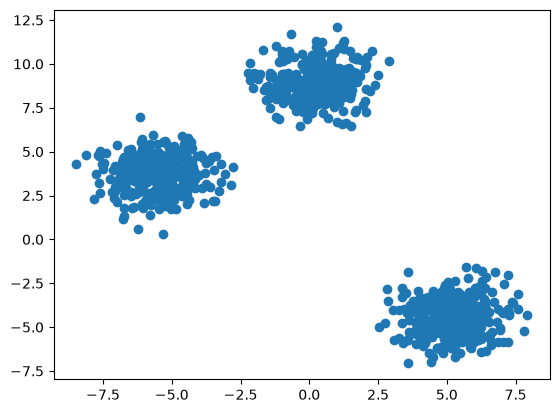

In [11]:
plt.scatter(X[:,0],X[:,1])

In [12]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.33, random_state=42)

In [13]:
from sklearn.cluster import KMeans

In [14]:
## Manual process
## Elbow method to select the k value

wcss=[]
for k in range(1,11):
    kmeans=KMeans(n_clusters=k,init='k-means++')
    kmeans.fit(X_train)
    wcss.append(kmeans.inertia_)

In [15]:
wcss

[34827.57682552022,
 7935.437286145418,
 1319.2730531585607,
 1194.109567760849,
 992.0708509383512,
 954.5011107741514,
 796.4504350569351,
 680.0516929014191,
 638.6735479266355,
 535.9448665506733]

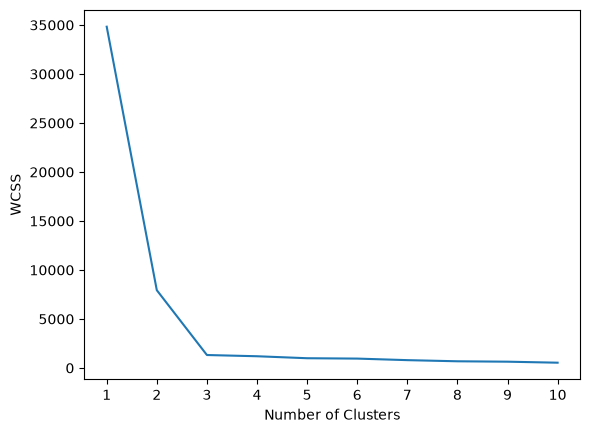

In [16]:
## PLOT ELBOW CURVE
plt.plot(range(1,11),wcss)
plt.xticks(range(1,11))
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.show()

In [17]:
kmeans=KMeans(n_clusters=3,init="k-means++")

In [19]:
y_labels=kmeans.fit_predict(X_train)

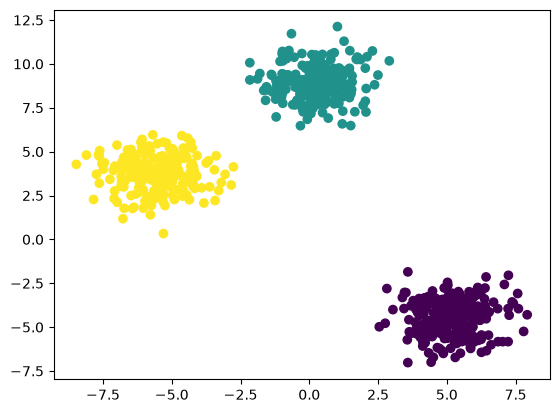

In [20]:
plt.scatter(X_train[:,0],X_train[:,1],c=y_labels)

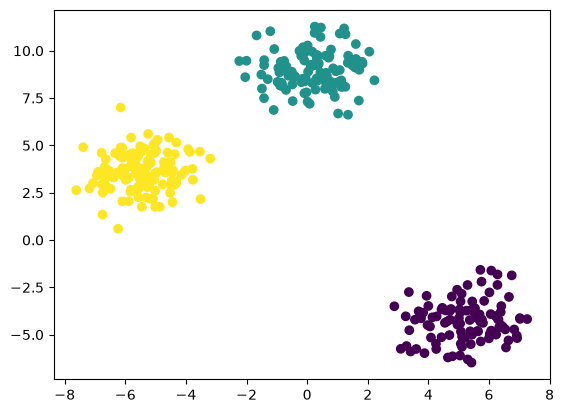

In [23]:
y_test_label=kmeans.predict(X_test)
plt.scatter(X_test[:,0],X_test[:,1],c=y_test_label)

In [24]:
## Knee locator finds the value of k automatically in case of large dataset
from kneed import KneeLocator

In [25]:
# since the curve is decreasing when k increases, we use convex otherwise we use concave
kl=KneeLocator(range(1,11),wcss,curve='convex',direction='decreasing')
kl.elbow

np.int64(3)

In [26]:
# performance metrics we use silhouette score
from sklearn.metrics import silhouette_score
silhouette_coefficients=[]
for k in range(2,11):
    kmeans=KMeans(n_clusters=k,init='k-means++')
    kmeans.fit(X_train)
    score=silhouette_score(X_train,kmeans.labels_)
    silhouette_coefficients.append(score)

In [27]:
silhouette_coefficients

[0.7281443868598331,
 0.8071181203797672,
 0.6505454471731087,
 0.5033057487405496,
 0.33592523624774034,
 0.32844379645477656,
 0.3347239217873905,
 0.3462171718700246,
 0.33250109785858367]

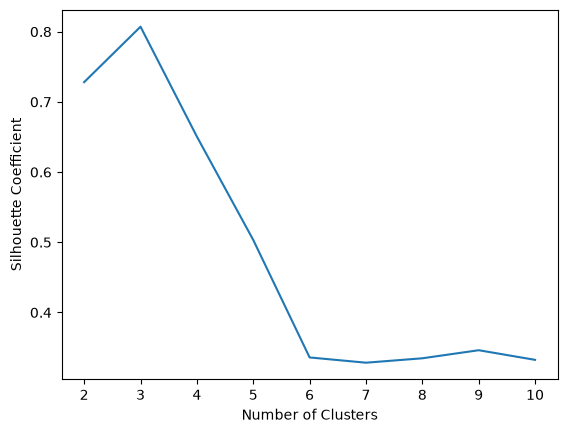

In [28]:
# plot silhouette score
plt.plot(range(2,11),silhouette_coefficients)
plt.xticks(range(2,11))
plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Coefficient")
plt.show()